# 4. TF-IDF representations, regularised Logistic Regression and Linear SVM

**Question for this notebook:** with the vocabulary and all learned preprocessing fitted on
`train` only, which representation / model / regularisation setting gives the best macro-F1
on `val`, and how does Lasso (L1) sparsity trade off against accuracy?

**Protocol (pre-declared, see `src/config.py`)**
* fit on the official `train` split (14,341 arguments)
* select on the official `val` split (1,768) with **macro-F1** as the primary metric (all 16
  fallacies count equally, so rare classes are not drowned out by Slippery Slope)
* the `test` split is **not loaded** in notebooks 04–07; it is used once, in notebook 08.

In [1]:
import sys, json, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from src.config import RESULTS, FIGURES, SEED
from src.data import load_dataset, get_splits
from src.features import word_bow, word_tfidf
from src.models import logreg, linear_svm, PriorBaseline, StratifiedRandomBaseline, scores_of
from src.evaluate import scores, per_class_f1

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]
X_va, Y_va, _ = S["val"]
del S["test"]                      # test split deliberately dropped here
print(len(X_tr), len(X_va), Y_tr.shape)

14341 1768 (14341, 16)


## 4.1 Baselines
* **Most-frequent-label**: predict *Slippery Slope* for every argument. A literal
  "all-zeros" majority predictor scores macro-F1 = 0 because every label is a minority class,
  so this is the strongest no-information rule.
* **Stratified random**: predict each label independently with its train prevalence.
* **Unigram BoW + Logistic Regression** (the notebook-03 baseline, reproduced here so every
  model below is compared under identical code).

In [2]:
rows = []
def record(name, family, model, Xa, Xb, extra=None):
    t = time.time(); model.fit(Xa, Y_tr); fit_s = time.time() - t
    pred = model.predict(Xb)
    try:
        sc = scores_of(model, Xb)
    except Exception:
        sc = None
    r = {"model": name, "family": family, **scores(Y_va, pred, sc), "fit_seconds": round(fit_s, 2)}
    if extra: r.update(extra)
    rows.append(r)
    return model, pred

dummy = np.zeros((len(X_tr), 1)); dummy_va = np.zeros((len(X_va), 1))
record("Most-frequent label", "baseline", PriorBaseline(), dummy, dummy_va)
record("Stratified random", "baseline", StratifiedRandomBaseline(), dummy, dummy_va)

bow = word_bow(); B_tr = bow.fit_transform(X_tr); B_va = bow.transform(X_va)
record("Unigram BoW + LR (nb03)", "baseline", logreg("l2", 1.0), B_tr, B_va)
pd.DataFrame(rows)[["model", "macro_f1", "micro_f1", "hamming_loss"]]

,model,macro_f1,micro_f1,hamming_loss
0,Most-frequent label,0.027126,0.239726,0.109870
1,Stratified random,0.084984,0.152308,0.140872
2,Unigram BoW + LR (nb03),0.764116,0.797407,0.030932


## 4.2 TF-IDF grid
TF-IDF uses sublinear term frequency (`1 + log tf`) and L2 row normalisation. The IDF
weights and vocabulary are learned from `train` only and then applied to `val`.

Grid: n-grams {(1,1), (1,2)} × penalty {L1, L2} × C {0.1, 1, 10, 100} × class weight
{none, balanced}, plus Linear SVM with C {0.1, 1, 10} × class weight.
`C` is the inverse regularisation strength: the L1 objective is
$\min_w \|w\|_1 + C\sum_i \log(1+e^{-y_i w^\top x_i})$, so small C forces more
coefficients to exactly zero.

In [3]:
reps = {}
for ng in [(1, 1), (1, 2)]:
    v = word_tfidf(ngram_range=ng)
    reps[ng] = (v, v.fit_transform(X_tr), None)
    reps[ng] = (v, reps[ng][1], v.transform(X_va))
    print(ng, "vocabulary:", reps[ng][1].shape[1])

for ng, (v, A, B) in reps.items():
    tag = "uni" if ng == (1, 1) else "uni+bi"
    for pen in ["l1", "l2"]:
        for C in [0.1, 1, 10, 100, 1000]:
            for cw in [None, "balanced"]:
                m, _ = record(f"TF-IDF {tag} LR-{pen.upper()} C={C} cw={cw}", f"LR-{pen.upper()}",
                              logreg(pen, C, cw), A, B,
                              {"ngram": tag, "penalty": pen, "C": C, "class_weight": str(cw)})
                coefs = np.vstack([e.coef_ for e in m.estimators_])
                rows[-1]["nonzero_frac"] = float((coefs != 0).mean())
    for C in [0.1, 1, 10]:
        for cw in [None, "balanced"]:
            record(f"TF-IDF {tag} LinearSVM C={C} cw={cw}", "LinearSVM", linear_svm(C, cw), A, B,
                   {"ngram": tag, "penalty": "l2-hinge", "C": C, "class_weight": str(cw)})

grid = pd.DataFrame(rows)
grid.to_csv(RESULTS / "val_grid_linear.csv", index=False)
grid.sort_values("macro_f1", ascending=False).head(12)[
    ["model", "macro_f1", "micro_f1", "macro_avg_precision", "nonzero_frac"]]

(1, 1) vocabulary: 6154


(1, 2) vocabulary: 38246


,model,macro_f1,micro_f1,macro_avg_precision,nonzero_frac
52,TF-IDF uni+bi LinearSVM C=1 cw=balanced,0.822855,0.833476,0.867281,NaN
53,TF-IDF uni+bi LinearSVM C=10 cw=None,0.815836,0.821429,0.858300,NaN
38,TF-IDF uni+bi LR-L1 C=1000 cw=balanced,0.815536,0.813196,0.860578,0.039692
54,TF-IDF uni+bi LinearSVM C=10 cw=balanced,0.811662,0.819342,0.860316,NaN
36,TF-IDF uni+bi LR-L1 C=100 cw=balanced,0.811143,0.809534,0.862486,0.032727
48,TF-IDF uni+bi LR-L2 C=1000 cw=balanced,0.810788,0.826097,0.854907,1.000000
46,TF-IDF uni+bi LR-L2 C=100 cw=balanced,0.810307,0.826096,0.849521,1.000000
44,TF-IDF uni+bi LR-L2 C=10 cw=balanced,0.805993,0.826593,0.863274,1.000000
34,TF-IDF uni+bi LR-L1 C=10 cw=balanced,0.801326,0.811333,0.864389,0.025890
37,TF-IDF uni+bi LR-L1 C=1000 cw=None,0.800209,0.808004,0.861840,0.042754


## 4.3 Best configuration per family (selected on validation macro-F1)

In [4]:
best = (grid[grid.family != "baseline"].sort_values("macro_f1", ascending=False)
        .groupby("family").head(1).sort_values("macro_f1", ascending=False))
best[["family", "model", "macro_f1", "micro_f1", "micro_precision", "micro_recall", "nonzero_frac"]]

,family,model,macro_f1,micro_f1,micro_precision,micro_recall,nonzero_frac
52,LinearSVM,TF-IDF uni+bi LinearSVM C=1 cw=balanced,0.822855,0.833476,0.829915,0.837069,NaN
38,LR-L1,TF-IDF uni+bi LR-L1 C=1000 cw=balanced,0.815536,0.813196,0.824546,0.802155,0.039692
48,LR-L2,TF-IDF uni+bi LR-L2 C=1000 cw=balanced,0.810788,0.826097,0.845286,0.807759,1.000000


## 4.4 Lasso regularisation path: sparsity vs. macro-F1
Each point is one L1 model. Moving right (larger C) relaxes the penalty, so more
coefficients survive. The interesting question is how few tokens are needed before
accuracy saturates.

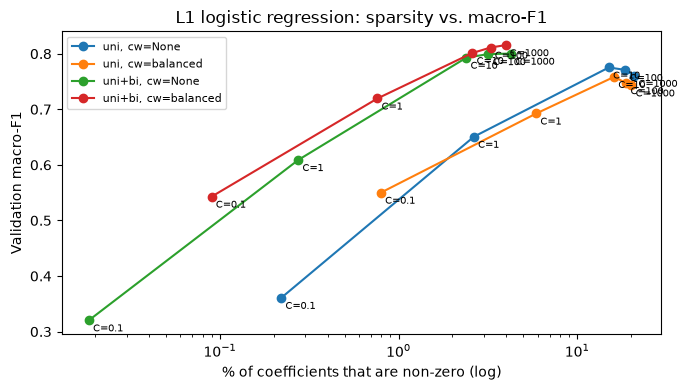

In [5]:
l1 = grid[(grid.family == "LR-L1")]
fig, ax = plt.subplots(figsize=(7, 4))
for (tag, cw), g in l1.groupby(["ngram", "class_weight"]):
    g = g.sort_values("C")
    ax.plot(g.nonzero_frac * 100, g.macro_f1, marker="o", label=f"{tag}, cw={cw}")
    for _, r in g.iterrows():
        ax.annotate(f"C={r.C:g}", (r.nonzero_frac * 100, r.macro_f1), fontsize=7,
                    xytext=(3, -8), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("% of coefficients that are non-zero (log)")
ax.set_ylabel("Validation macro-F1"); ax.set_title("L1 logistic regression: sparsity vs. macro-F1")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIGURES / "l1_sparsity_path.png", dpi=150); plt.show()

## 4.5 Per-class validation F1 for the best model of each family vs. the BoW baseline
Class weighting mainly matters for the rare labels (Red Herring, Appeal to Ignorance,
Affirming the Consequent, Denying the Antecedent have 57–129 examples in total).

In [6]:
def refit(row):
    tag = row["ngram"]; v, A, B = reps[(1, 1) if tag == "uni" else (1, 2)]
    cw = None if row["class_weight"] == "None" else "balanced"
    m = (linear_svm(row["C"], cw) if row["family"] == "LinearSVM"
         else logreg(row["penalty"], row["C"], cw))
    m.fit(A, Y_tr)
    return m, m.predict(B)

per_class = {"Unigram BoW + LR (nb03)": per_class_f1(Y_va, logreg("l2", 1.0).fit(B_tr, Y_tr).predict(B_va))}
for _, r in best.iterrows():
    per_class[r["family"]] = per_class_f1(Y_va, refit(r)[1])
pc = pd.DataFrame(per_class, index=LABELS)
pc.insert(0, "val support", Y_va.sum(0))
pc.round(3)

,val support,Unigram BoW + LR (nb03),LinearSVM,LR-L1,LR-L2
Slippery Slope,490,0.886,0.891,0.878,0.884
Appeal to Authority,279,0.834,0.855,0.840,0.843
Bandwagon / Popularity,262,0.722,0.815,0.778,0.784
Hasty Generalization,213,0.717,0.793,0.771,0.778
False Cause / Causality,211,0.818,0.835,0.824,0.835
Appeal to Emotion,207,0.784,0.800,0.774,0.803
Composition,151,0.841,0.847,0.840,0.861
False Dilemma,139,0.751,0.794,0.749,0.809
Ad Hominem,129,0.667,0.762,0.683,0.749
Equivocation,81,0.800,0.821,0.837,0.822


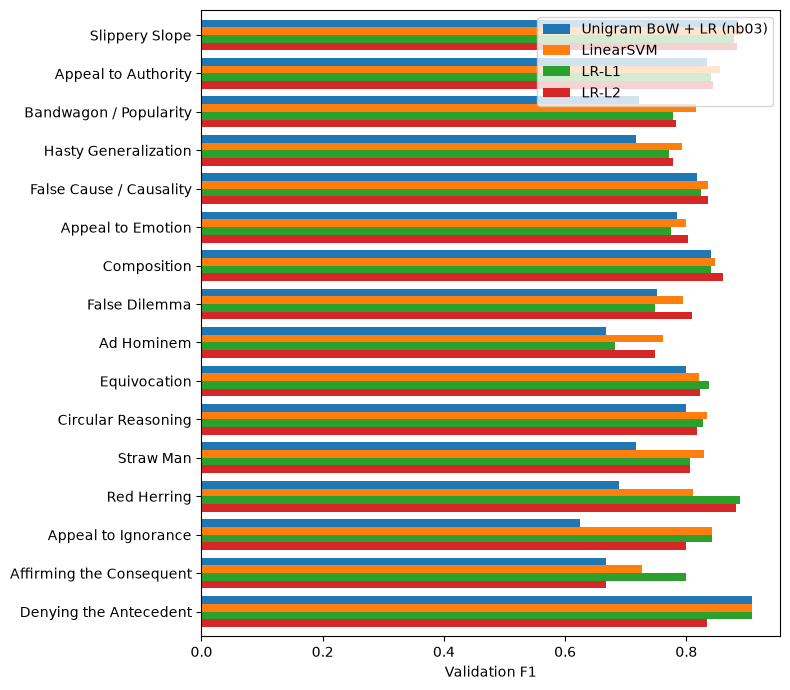

In [7]:
ax = pc.drop(columns="val support").plot.barh(figsize=(8, 7), width=0.8)
ax.set_xlabel("Validation F1"); ax.invert_yaxis(); plt.tight_layout()
plt.savefig(FIGURES / "per_class_val_f1.png", dpi=150); plt.show()

## 4.6 Save the selection
The chosen configurations are written to `results/selection.json`. Notebook 08 reads this
file and does **not** re-tune anything on the test split.

In [8]:
sel_path = RESULTS / "selection.json"
sel = json.loads(sel_path.read_text()) if sel_path.exists() else {}
for _, r in best.iterrows():
    sel[r["family"]] = {k: (None if (isinstance(r[k], float) and np.isnan(r[k])) else r[k])
                        for k in ["model", "ngram", "penalty", "C", "class_weight", "macro_f1"]}
sel_path.write_text(json.dumps(sel, indent=2, default=float))
print(json.dumps(sel, indent=2, default=float))

{
  "LinearSVM": {
    "model": "TF-IDF uni+bi LinearSVM C=1 cw=balanced",
    "ngram": "uni+bi",
    "penalty": "l2-hinge",
    "C": 1.0,
    "class_weight": "balanced",
    "macro_f1": 0.8228550924020248
  },
  "LR-L1": {
    "model": "TF-IDF uni+bi LR-L1 C=1000 cw=balanced",
    "ngram": "uni+bi",
    "penalty": "l1",
    "C": 1000.0,
    "class_weight": "balanced",
    "macro_f1": 0.8155356267687837
  },
  "LR-L2": {
    "model": "TF-IDF uni+bi LR-L2 C=1000 cw=balanced",
    "ngram": "uni+bi",
    "penalty": "l2",
    "C": 1000.0,
    "class_weight": "balanced",
    "macro_f1": 0.8107884067165241
  },
  "PCA-LR": {
    "model": "SVD-1000 + LR cw=None",
    "k": 1000,
    "C": 1.0,
    "class_weight": "None",
    "macro_f1": 0.7686393230640249
  },
  "RBF-SVM": {
    "model": "SVD-300 + RBF-SVM C=10 cw=balanced",
    "k": 300,
    "C": 10.0,
    "class_weight": "balanced",
    "macro_f1": 0.7894359130522337
  },
  "thresholds": {
    "model": "Calibrated LinearSVM",
    "f1_tuned_on